# WS1 — ผลการพยากรณ์ยอดขาย (Rossmann)

เทียบ 4 โมเดลบนช่วง Validation (2015-05-09 ถึง 2015-06-19) และ Test (2015-06-20 ถึง 2015-07-31)
ทุกโมเดลพยากรณ์ทีละ 14 วันจาก 3 จุดตั้งต้นต่อช่วง วัดผลเฉพาะวันที่ร้านเปิด (`is_eval_day = 1`)

รันใหม่หลังเทรน: `python -m ai.cashflow_forecast.train` แล้ว `python -m ai.cashflow_forecast.evaluate`

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from ai.cashflow_forecast.evaluate import results_table, wape
from ai.cashflow_forecast.train import HORIZON, TEST_ORIGINS, VAL_ORIGINS

MODELS = ["seasonal_naive", "lightgbm", "lstm", "gru", "ensemble"]
LABELS = {"seasonal_naive": "Seasonal naive", "lightgbm": "LightGBM", "lstm": "LSTM", "gru": "GRU",
          "ensemble": "LSTM+GRU"}
# Categorical slots 1–5 in fixed order; each model keeps its colour in every chart.
COLORS = {"seasonal_naive": "#2a78d6", "lightgbm": "#eb6834", "lstm": "#1baf7a", "gru": "#eda100",
          "ensemble": "#e87ba4"}
INK, INK_2, GRID = "#0b0b0b", "#52514e", "#e4e3df"

plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": INK_2, "ytick.color": INK_2, "ytick.left": False,
    "legend.frameon": False, "lines.linewidth": 1.6, "font.size": 10,
    # Thai-capable fonts on macOS / Windows / Linux, then the default.
    "font.family": ["Thonburi", "Sukhumvit Set", "Leelawadee UI", "Tahoma", "Noto Sans Thai", "DejaVu Sans"],
})
import logging
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)  # quiet "font not found" for other OSes

In [2]:
data = pd.read_parquet(ROOT / "data/processed/rossmann.parquet")
preds = pd.concat(
    [pd.read_parquet(ROOT / f"models/predictions/{m}.parquet") for m in MODELS], ignore_index=True
)
df = preds.merge(
    data[["store", "date", "sales", "is_eval_day", "day_of_week", "promo", "open"]],
    on=["store", "date"],
)
ev = df[df["is_eval_day"] == 1].copy()

origins = {"val": VAL_ORIGINS, "test": TEST_ORIGINS}
def horizon_day(row_dates, split):
    start = origins[split][0]
    return ((row_dates - start).dt.days - 1) % HORIZON + 1
ev["horizon"] = 0
for split in ("val", "test"):
    m = ev["split"] == split
    ev.loc[m, "horizon"] = horizon_day(ev.loc[m, "date"], split)

def group_wape(frame, by):
    g = frame.assign(err=(frame["forecast"] - frame["sales"]).abs()).groupby(by)
    return g["err"].sum() / g["sales"].sum()

## 1. ตารางเทียบโมเดล

In [3]:
table = results_table()
table["model"] = table["model"].map(LABELS)
table.style.format({"wape": "{:.2%}", "mae": "{:,.0f}", "rmse": "{:,.0f}", "n_days": "{:,}"}).hide(axis="index")

model,split,wape,mae,rmse,n_days
Seasonal naive,test,22.39%,"1,563","2,206","40,282"
LightGBM,test,8.23%,574,855,"40,282"
LSTM,test,8.54%,596,894,"40,282"
GRU,test,8.28%,578,867,"40,282"
LSTM+GRU,test,8.18%,571,862,"40,282"
Seasonal naive,val,18.86%,"1,373","1,910","37,472"
LightGBM,val,7.91%,576,804,"37,472"
LSTM,val,7.19%,524,726,"37,472"
GRU,val,7.37%,536,738,"37,472"
LSTM+GRU,val,7.08%,516,714,"37,472"


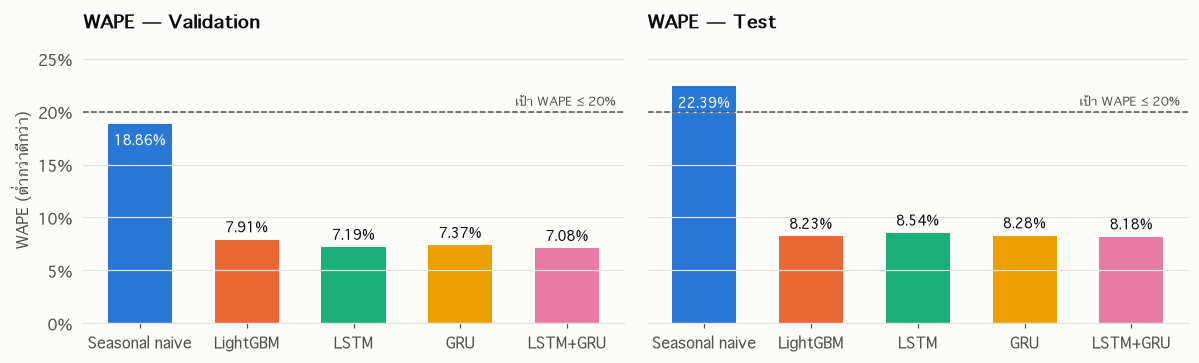

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
scores = group_wape(ev, ["split", "model"])
for ax, split, title in zip(axes, ("val", "test"), ("Validation", "Test")):
    vals = [scores[(split, m)] for m in MODELS]
    bars = ax.bar([LABELS[m] for m in MODELS], vals, color=[COLORS[m] for m in MODELS], width=0.6)
    for bar, v in zip(bars, vals):
        # Tall bars carry the label inside so it never sits on the target line.
        inside = v > 0.15
        ax.text(bar.get_x() + bar.get_width() / 2, v - 0.008 if inside else v + 0.004, f"{v:.2%}",
                ha="center", va="top" if inside else "bottom", fontsize=9,
                color="#ffffff" if inside else INK)
    ax.axhline(0.20, color=INK_2, lw=1, ls="--")
    ax.text(4.45, 0.203, "เป้า WAPE ≤ 20%", ha="right", va="bottom", color=INK_2, fontsize=8)
    ax.set_ylim(0, 0.27)
    ax.set_title(f"WAPE — {title}")
    ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
axes[0].set_ylabel("WAPE (ต่ำกว่าดีกว่า)")
fig.tight_layout()

## 2. ยอดขายจริง เทียบค่าพยากรณ์ (ช่วง Test)

โมเดลหลักคือ LSTM+GRU (ค่าเฉลี่ย) เลือก 4 ร้าน: ร้านที่โมเดลหลักพยากรณ์ดีสุด, ค่ากลาง, แย่สุด และร้านใหญ่สุด เส้นประแนวตั้งคือจุดตั้งต้นการพยากรณ์ 14 วันแต่ละรอบ

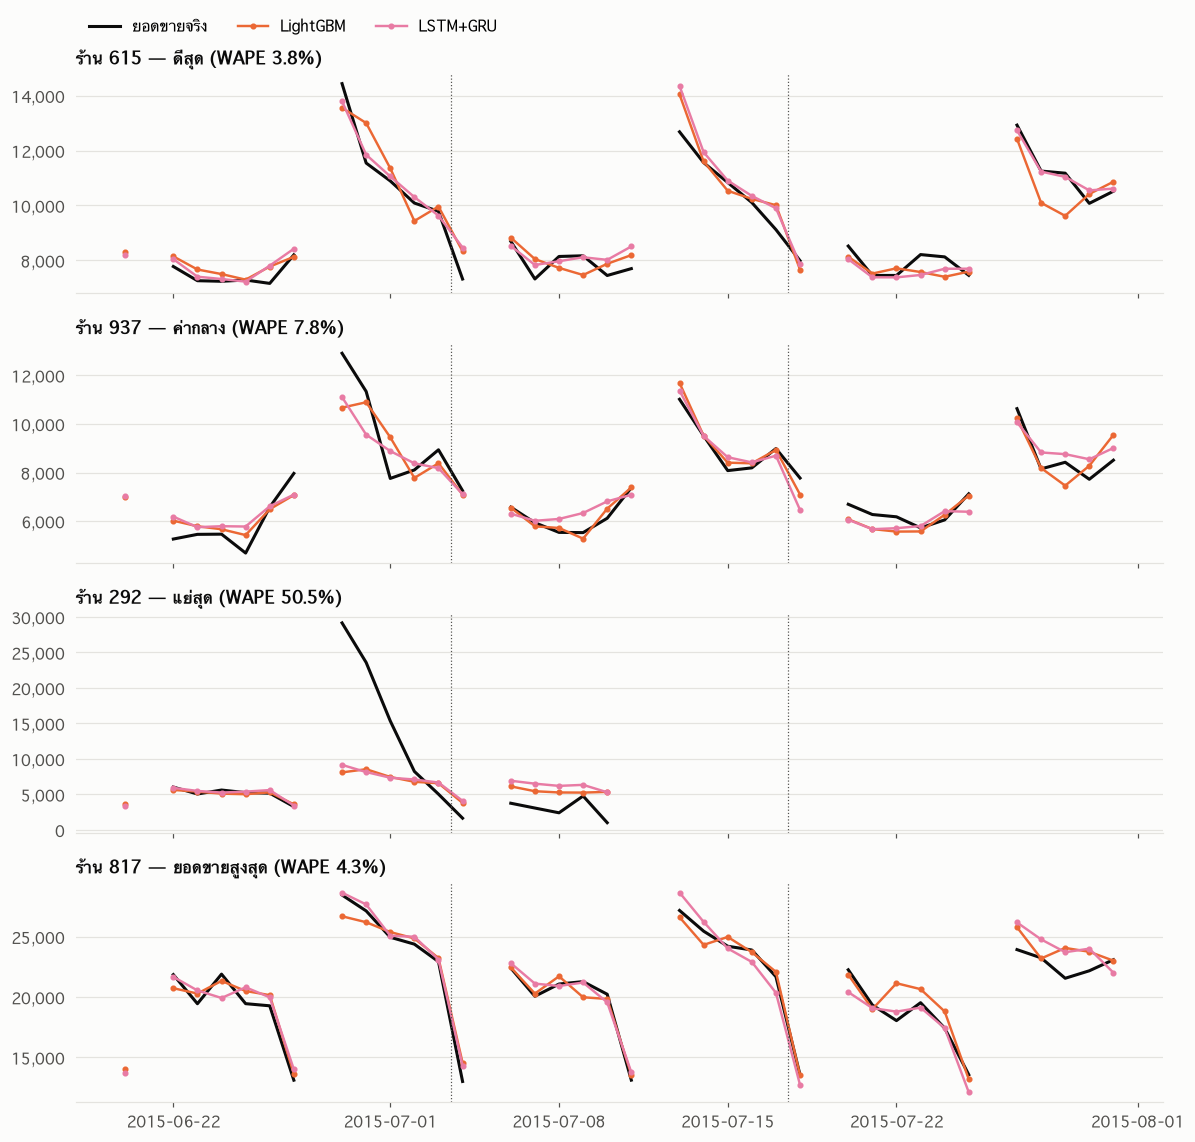

In [5]:
test = df[df["split"] == "test"]
store_wape = group_wape(ev[(ev["split"] == "test") & (ev["model"] == "ensemble")], "store").sort_values()
biggest = data.groupby("store")["store_mean_sales"].first().idxmax()
picks = {
    "ดีสุด": store_wape.index[0],
    "ค่ากลาง": store_wape.index[len(store_wape) // 2],
    "แย่สุด": store_wape.index[-1],
    "ยอดขายสูงสุด": biggest,
}

fig, axes = plt.subplots(len(picks), 1, figsize=(11, 2.6 * len(picks)), sharex=True)
for ax, (label, store) in zip(axes, picks.items()):
    s = test[test["store"] == store]
    actual = s[s["model"] == "ensemble"].set_index("date")
    ax.plot(actual.index, actual["sales"].where(actual["open"] == 1), color=INK, lw=2, label="ยอดขายจริง")
    for m in ("lightgbm", "ensemble"):
        f = s[s["model"] == m].set_index("date")["forecast"].where(actual["open"] == 1)
        ax.plot(f.index, f, color=COLORS[m], label=LABELS[m], marker="o", ms=3)
    for o in TEST_ORIGINS[1:]:
        ax.axvline(o + pd.Timedelta(hours=12), color=INK_2, lw=0.8, ls=":")
    ax.set_title(f"ร้าน {store} — {label} (WAPE {store_wape[store]:.1%})", fontsize=11)
    ax.yaxis.set_major_formatter(lambda v, _: f"{v:,.0f}")
axes[0].legend(loc="upper left", ncol=3, bbox_to_anchor=(0, 1.32))
fig.tight_layout()

## 3. ความแม่นตามระยะพยากรณ์และวันในสัปดาห์

ไม่รวม seasonal naive เพราะ error สูงกว่ามาก (สเกลจะบีบโมเดลอื่นจนอ่านไม่ออก)

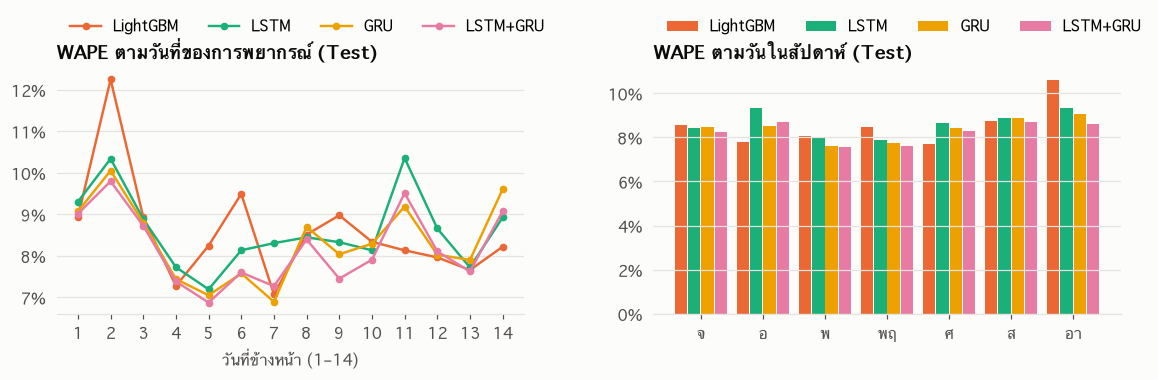

In [6]:
learned = ["lightgbm", "lstm", "gru", "ensemble"]
t = ev[(ev["split"] == "test") & ev["model"].isin(learned)]
by_h = group_wape(t, ["model", "horizon"]).unstack(0)
by_dow = group_wape(t, ["model", "day_of_week"]).unstack(0)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for m in learned:
    axes[0].plot(by_h.index, by_h[m], color=COLORS[m], marker="o", ms=4, label=LABELS[m])
axes[0].set_title("WAPE ตามวันที่ของการพยากรณ์ (Test)")
axes[0].set_xlabel("วันที่ข้างหน้า (1–14)")
axes[0].set_xticks(range(1, HORIZON + 1))
axes[0].legend(loc="lower left", bbox_to_anchor=(0, 1.08), ncol=4)

x = np.arange(len(by_dow.index))
w = 0.2
for i, m in enumerate(learned):
    axes[1].bar(x + (i - 1.5) * (w + 0.015), by_dow[m], width=w, color=COLORS[m], label=LABELS[m])
axes[1].set_xticks(x, ["จ", "อ", "พ", "พฤ", "ศ", "ส", "อา"][: len(x)])
axes[1].set_title("WAPE ตามวันในสัปดาห์ (Test)")
axes[1].legend(loc="lower left", bbox_to_anchor=(0, 1.08), ncol=4)
for ax in axes:
    ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
fig.tight_layout()

## 4. WAPE รายร้าน: LSTM+GRU เทียบ LightGBM (ช่วง Test)

จุดใต้เส้นทแยง = ร้านที่ LSTM+GRU แม่นกว่า

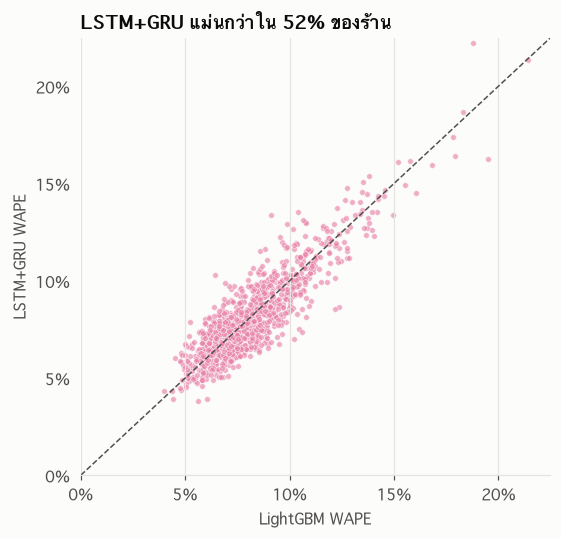

In [7]:
per_store = group_wape(ev[ev["split"] == "test"], ["store", "model"]).unstack()
fig, ax = plt.subplots(figsize=(5.2, 5))
ax.scatter(per_store["lightgbm"], per_store["ensemble"], s=14, color=COLORS["ensemble"], alpha=0.6,
           edgecolor="#fcfcfb", linewidth=0.5)
lim = float(np.nanpercentile(per_store[["lightgbm", "ensemble"]].to_numpy(), 99.5)) * 1.05
ax.plot([0, lim], [0, lim], color=INK_2, lw=1, ls="--")
ax.set_xlim(0, lim); ax.set_ylim(0, lim)
ax.grid(axis="both")
ax.set_xlabel("LightGBM WAPE"); ax.set_ylabel("LSTM+GRU WAPE")
for axis in (ax.xaxis, ax.yaxis):
    axis.set_major_locator(plt.MultipleLocator(0.05))
    axis.set_major_formatter(lambda v, _: f"{v:.0%}")
share = (per_store["ensemble"] < per_store["lightgbm"]).mean()
ax.set_title(f"LSTM+GRU แม่นกว่าใน {share:.0%} ของร้าน")
fig.tight_layout()

## 5. ผล tuning (เลือกจาก Validation เท่านั้น)

LSTM+GRU คือค่าเฉลี่ยของ LSTM และ GRU ที่ดีที่สุด (น้ำหนักเท่ากัน ไม่ได้ fit อะไรเพิ่ม)
ตั้งกติกาไว้ก่อนดู Test: ใช้ ensemble ถ้า val WAPE ดีกว่าโมเดลเดี่ยวที่ดีที่สุด — ได้ 7.08% เทียบ LSTM 7.19%

In [8]:
for cell in ("lstm", "gru"):
    path = ROOT / f"models/tuning_{cell}.csv"
    if path.exists():
        display(pd.read_csv(path).style.format({"val_wape": "{:.2%}"}).hide(axis="index")
                .set_caption(cell.upper()))
    else:
        print(f"{path.name}: ยังไม่มี — รัน python -m ai.cashflow_forecast.train --tune")

config,window,hidden,layers,val_wape
lstm_w56_h128_l1,56,128,1,7.19%
lstm_w56_h64_l2,56,64,2,7.35%
lstm_w28_h64_l2,28,64,2,7.55%
lstm_w56_h128_l2,56,128,2,7.61%
lstm_w56_h64_l1,56,64,1,7.68%
lstm_w28_h128_l2,28,128,2,7.90%
lstm_w28_h128_l1,28,128,1,8.08%
lstm_w28_h64_l1,28,64,1,8.08%


config,window,hidden,layers,val_wape
gru_w28_h128_l2,28,128,2,7.37%
gru_w28_h128_l1,28,128,1,7.41%
gru_w56_h128_l1,56,128,1,7.63%
gru_w28_h64_l2,28,64,2,7.67%
gru_w28_h64_l1,28,64,1,7.73%
gru_w56_h64_l2,56,64,2,7.75%
gru_w56_h64_l1,56,64,1,7.82%
gru_w56_h128_l2,56,128,2,7.87%
